### Part A: Retrain reduced 5-feature PIDD models

In [ ]:
#1 Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)

DRIVE_PATH = "/content/drive/MyDrive/Capstone/"

In [ ]:
#2 Loading PIDD's original cleaned data, subsetting to the 5 shared features
shared_features = ["Glucose", "BloodPressure", "BMI", "Insulin", "Age"]

X_train_pidd = pd.read_csv(DRIVE_PATH + "X_train_clean.csv")[shared_features]
X_test_pidd = pd.read_csv(DRIVE_PATH + "X_test_clean.csv")[shared_features]
y_train_pidd = pd.read_csv(DRIVE_PATH + "y_train_clean.csv").squeeze()
y_test_pidd = pd.read_csv(DRIVE_PATH + "y_test_clean.csv").squeeze()

print("PIDD reduced train shape:", X_train_pidd.shape)
print("PIDD reduced test shape :", X_test_pidd.shape)

cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

PIDD reduced train shape: (614, 5)
PIDD reduced test shape : (154, 5)


In [ ]:
#3 Logistic Regression — 5-feature PIDD variant
lr_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("clf", LogisticRegression(random_state=42, max_iter=2000))
])

param_grid_lr = [
    {"clf__solver": ["liblinear"], "clf__penalty": ["l1", "l2"], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"clf__solver": ["saga"], "clf__penalty": ["elasticnet"], "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]}
]

lr_search = GridSearchCV(lr_pipeline, param_grid_lr, scoring="roc_auc", cv=cv_strategy, n_jobs=-1, verbose=1)
lr_search.fit(X_train_pidd, y_train_pidd)

print("Best LR Parameters:", lr_search.best_params_)
print("Best CV ROC-AUC:", lr_search.best_score_)

best_lr_reduced = lr_search.best_estimator_

Fitting 10 folds for each of 42 candidates, totalling 420 fits
Best LR Parameters: {'clf__C': 0.1, 'clf__l1_ratio': 0.3, 'clf__penalty': 'elasticnet', 'clf__solver': 'saga'}
Best CV ROC-AUC: 0.8344805194805194


In [ ]:
#4 Random Forest — 5-feature PIDD variant
rf_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_dist_rf = {
    "clf__n_estimators": [100, 200, 300, 400, 500],
    "clf__max_depth": [None, 5, 10, 15, 20],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2"],
    "clf__bootstrap": [True, False]
}

rf_search = RandomizedSearchCV(rf_pipeline, param_dist_rf, n_iter=50, scoring="roc_auc", cv=cv_strategy, random_state=42, n_jobs=-1, verbose=1)
rf_search.fit(X_train_pidd, y_train_pidd)

print("Best RF Parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:", rf_search.best_score_)

best_rf_reduced = rf_search.best_estimator_

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best RF Parameters: {'clf__n_estimators': 500, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 1, 'clf__max_features': 'log2', 'clf__max_depth': 5, 'clf__bootstrap': True}
Best CV ROC-AUC: 0.8332521645021644


In [ ]:
#5 XGBoost — 5-feature PIDD variant
xgb_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=-1))
])

param_dist_xgb = {
    "clf__n_estimators": [100, 200, 300, 400, 500],
    "clf__max_depth": [3, 4, 5, 6, 8],
    "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "clf__subsample": [0.6, 0.8, 1.0],
    "clf__colsample_bytree": [0.6, 0.8, 1.0],
    "clf__min_child_weight": [1, 3, 5],
    "clf__gamma": [0, 0.1, 0.3],
    "clf__reg_alpha": [0, 0.1, 1],
    "clf__reg_lambda": [1, 1.5, 2]
}

xgb_search = RandomizedSearchCV(xgb_pipeline, param_dist_xgb, n_iter=50, scoring="roc_auc", cv=cv_strategy, random_state=42, n_jobs=-1, verbose=1)
xgb_search.fit(X_train_pidd, y_train_pidd)

print("Best XGB Parameters:", xgb_search.best_params_)
print("Best CV ROC-AUC:", xgb_search.best_score_)

best_xgb_reduced = xgb_search.best_estimator_

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best XGB Parameters: {'clf__subsample': 0.6, 'clf__reg_lambda': 2, 'clf__reg_alpha': 1, 'clf__n_estimators': 200, 'clf__min_child_weight': 3, 'clf__max_depth': 3, 'clf__learning_rate': 0.01, 'clf__gamma': 0.1, 'clf__colsample_bytree': 1.0}
Best CV ROC-AUC: 0.8354274891774892


In [ ]:
#6 Evaluating all three reduced models on PIDD's OWN test set
# This is the "home turf" reference point — how well does each 5-feature
# model do on the same kind of data (PIDD) it was trained on, before we
# ask how it does on a completely different population (NHANES)?
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

pidd_reduced_results = pd.DataFrame([
    evaluate_model(best_lr_reduced, X_test_pidd, y_test_pidd, "LR (5-feature, on PIDD)"),
    evaluate_model(best_rf_reduced, X_test_pidd, y_test_pidd, "RF (5-feature, on PIDD)"),
    evaluate_model(best_xgb_reduced, X_test_pidd, y_test_pidd, "XGB (5-feature, on PIDD)")
])
print(pidd_reduced_results.round(4))

                      Model  Accuracy  Precision  Recall      F1  ROC-AUC
0   LR (5-feature, on PIDD)    0.7013     0.5645  0.6481  0.6034   0.7844
1   RF (5-feature, on PIDD)    0.7273     0.5811  0.7963  0.6719   0.8207
2  XGB (5-feature, on PIDD)    0.7273     0.5811  0.7963  0.6719   0.8157


In [ ]:
#7 Saving the reduced models — clearly named to distinguish from the
# original 8-feature versions
joblib.dump(best_lr_reduced, DRIVE_PATH + "models/logistic_regression_5feature_pipeline.pkl")
joblib.dump(best_rf_reduced, DRIVE_PATH + "models/random_forest_5feature_pipeline.pkl")
joblib.dump(best_xgb_reduced, DRIVE_PATH + "models/xgboost_5feature_pipeline.pkl")
print("Reduced models saved")

Reduced models saved


## Part B: True external validation on NHANES

In [ ]:
DRIVE_PATH = "/content/drive/MyDrive/Capstone/Data_2/"

In [ ]:
#8 Loading the NHANES core test set
X_test_nhanes = pd.read_csv(DRIVE_PATH + "NHANES_X_test_clean.csv")
y_test_nhanes = pd.read_csv(DRIVE_PATH + "NHANES_y_test_clean.csv").squeeze()

# Enforce identical column order to what the models were fit on —
# sklearn will validate this automatically, but making it explicit here
# avoids relying on that check silently catching a mistake
X_test_nhanes = X_test_nhanes[shared_features]

print("NHANES test shape:", X_test_nhanes.shape)

NHANES test shape: (481, 5)


In [ ]:
#9 Applying the PIDD-trained models to NHANES, completely unchanged —
# no refitting, no re-tuning. This is the actual external validation test.
nhanes_external_results = pd.DataFrame([
    evaluate_model(best_lr_reduced, X_test_nhanes, y_test_nhanes, "LR (PIDD-trained, on NHANES)"),
    evaluate_model(best_rf_reduced, X_test_nhanes, y_test_nhanes, "RF (PIDD-trained, on NHANES)"),
    evaluate_model(best_xgb_reduced, X_test_nhanes, y_test_nhanes, "XGB (PIDD-trained, on NHANES)")
])
print(nhanes_external_results.round(4))

                           Model  Accuracy  Precision  Recall      F1  ROC-AUC
0   LR (PIDD-trained, on NHANES)    0.8212     0.5461    0.83  0.6587   0.9070
1   RF (PIDD-trained, on NHANES)    0.8046     1.0000    0.06  0.1132   0.8807
2  XGB (PIDD-trained, on NHANES)    0.8815     0.8028    0.57  0.6667   0.8899


In [ ]:
#10 Direct comparison: home turf (PIDD) vs away turf (NHANES), same models
comparison = pd.concat([
    pidd_reduced_results.set_index("Model"),
    nhanes_external_results.set_index("Model")
])
print(comparison.round(4))

                               Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                                      
LR (5-feature, on PIDD)          0.7013     0.5645  0.6481  0.6034   0.7844
RF (5-feature, on PIDD)          0.7273     0.5811  0.7963  0.6719   0.8207
XGB (5-feature, on PIDD)         0.7273     0.5811  0.7963  0.6719   0.8157
LR (PIDD-trained, on NHANES)     0.8212     0.5461  0.8300  0.6587   0.9070
RF (PIDD-trained, on NHANES)     0.8046     1.0000  0.0600  0.1132   0.8807
XGB (PIDD-trained, on NHANES)    0.8815     0.8028  0.5700  0.6667   0.8899


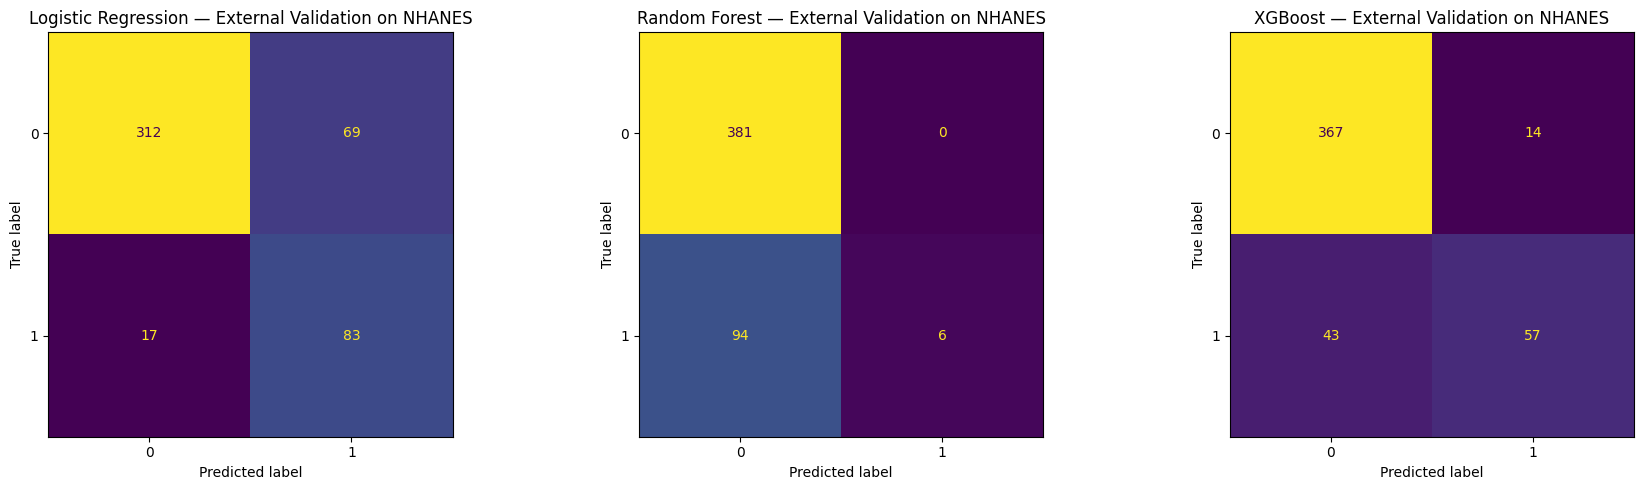

In [ ]:
#11 Confusion matrices for the external validation results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_preds = [
    ("Logistic Regression", best_lr_reduced),
    ("Random Forest", best_rf_reduced),
    ("XGBoost", best_xgb_reduced)
]

for ax, (name, model) in zip(axes, models_preds):
    y_pred = model.predict(X_test_nhanes)
    ConfusionMatrixDisplay.from_predictions(y_test_nhanes, y_pred, ax=ax, colorbar=False)
    ax.set_title(f"{name} — External Validation on NHANES")

plt.tight_layout()
plt.savefig(DRIVE_PATH + "G3_external_validation_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#12 Comparing feature distributions directly: PIDD vs NHANES training data
comparison_stats = pd.DataFrame({
    "PIDD_Glucose": X_train_pidd["Glucose"].describe(),
    "NHANES_Glucose": pd.read_csv(DRIVE_PATH + "NHANES_X_train_clean.csv")["Glucose"].describe(),
    "PIDD_Insulin": X_train_pidd["Insulin"].describe(),
    "NHANES_Insulin": pd.read_csv(DRIVE_PATH + "NHANES_X_train_clean.csv")["Insulin"].describe(),
})
print(comparison_stats.round(2))

       PIDD_Glucose  NHANES_Glucose  PIDD_Insulin  NHANES_Insulin
count        614.00         1920.00        614.00         1920.00
mean         121.67          114.09        148.35           14.67
std           30.00           36.50         90.16           21.56
min           56.00           47.00         15.00            0.71
25%           99.00           97.00         87.00            6.44
50%          117.00          104.00        129.43            9.96
75%          140.00          115.00        187.11           15.59
max          199.00          421.00        744.00          485.10


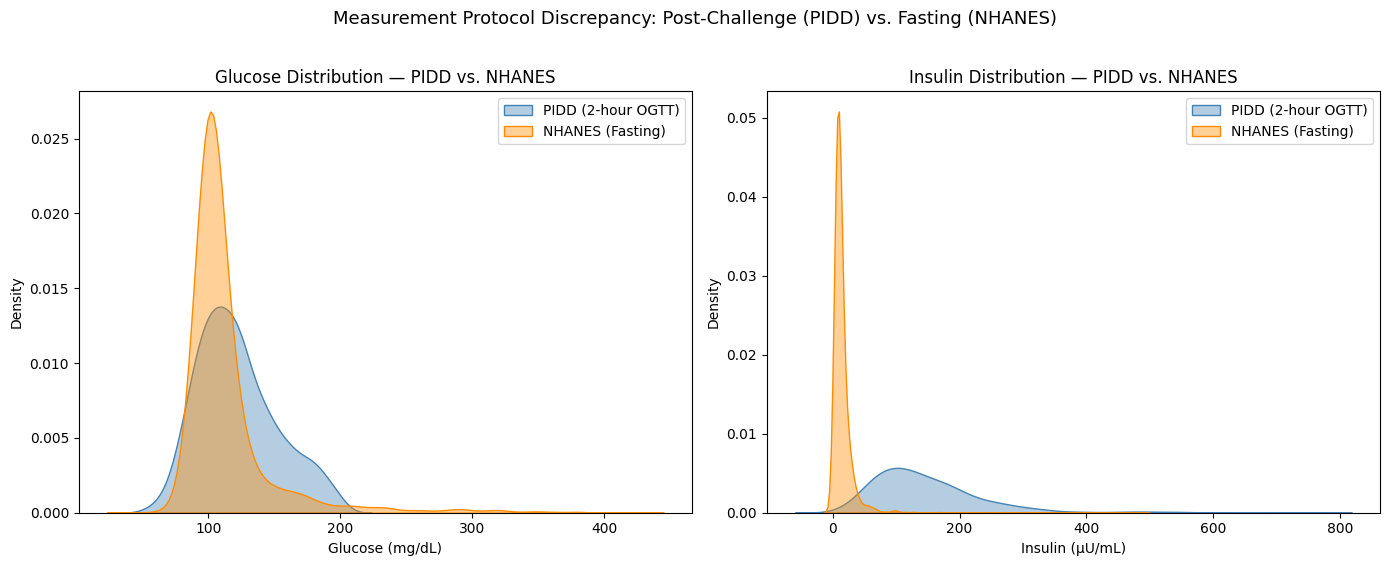

In [ ]:
#Overlaid distribution plots, PIDD vs. NHANES, Glucose and Insulin
import matplotlib.pyplot as plt
import seaborn as sns

# Load both training sets fresh, so this cell is self-contained regardless
# of what's currently in memory
X_train_pidd_full = pd.read_csv("/content/drive/MyDrive/Capstone/X_train_clean.csv")
X_train_nhanes = pd.read_csv("/content/drive/MyDrive/Capstone/Data_2/NHANES_X_train_clean.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Glucose ---
sns.kdeplot(X_train_pidd_full["Glucose"], fill=True, alpha=0.4, color="steelblue",
            label="PIDD (2-hour OGTT)", ax=axes[0])
sns.kdeplot(X_train_nhanes["Glucose"], fill=True, alpha=0.4, color="darkorange",
            label="NHANES (Fasting)", ax=axes[0])
axes[0].set_title("Glucose Distribution — PIDD vs. NHANES")
axes[0].set_xlabel("Glucose (mg/dL)")
axes[0].legend()

# --- Insulin ---
sns.kdeplot(X_train_pidd_full["Insulin"], fill=True, alpha=0.4, color="steelblue",
            label="PIDD (2-hour OGTT)", ax=axes[1])
sns.kdeplot(X_train_nhanes["Insulin"], fill=True, alpha=0.4, color="darkorange",
            label="NHANES (Fasting)", ax=axes[1])
axes[1].set_title("Insulin Distribution — PIDD vs. NHANES")
axes[1].set_xlabel("Insulin (µU/mL)")
axes[1].legend()

plt.suptitle("Measurement Protocol Discrepancy: Post-Challenge (PIDD) vs. Fasting (NHANES)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(DRIVE_PATH + "Figure_5_4_PIDD_vs_NHANES_distributions.png", dpi=300, bbox_inches="tight")
plt.show()